# Laporan UTS Graf Sains Data  

**Mata Kuliah:** Graf Sains Data  
**Topik:** Pengenalan Driver Neo4j dan Checkpoint  
**Nama:** Fio Octriyanti  
**Program Studi:** S1 Sains Data Universitas Negeri Surabaya

# 1. Pendahuluan

## 1.1 Persiapan koneksi ke Neo4j

In [5]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = "Fioula111005"

driver = GraphDatabase.driver(URI, auth=(USERNAME, PASSWORD))
driver.verify_connectivity()
print("Koneksi ke Neo4j berhasil.")

Koneksi ke Neo4j berhasil.


/var/folders/0f/6_frks_90fgc2lr_bz3gp0dm0000gn/T/ipykernel_85228/1200178453.py:8: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


## 1.2 Membuat graf pertemanan sesuai tutorial

In [6]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            """
            MERGE (a:Person {name: $name})
            MERGE (friend:Person {name: $friend_name})
            MERGE (a)-[:KNOWS]->(friend)
            """,
            name=name,
            friend_name=friend_name,
        )

def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            """
            MATCH (a:Person)-[:KNOWS]->(friend)
            WHERE a.name = $name
            RETURN friend.name AS friend_name
            ORDER BY friend.name
            """,
            name=name,
        )
        return [record["friend_name"] for record in result]

add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")

friends = print_friends(driver, "Arthur")
print("Teman Arthur:", friends)

Teman Arthur: ['Guinevere', 'Lancelot', 'Merlin']


### Pertanyaan 1 : Apa nama database yang digunakan pada tutorial ini?

**Jawaban:** Database yang digunakan adalah **`neo4j`**. Hal ini terlihat pada contoh driver yang menjalankan operasi terhadap database dengan parameter `database_="neo4j"` atau membuka session dengan `database="neo4j"`. Database `system` pada Neo4j digunakan untuk administrasi DBMS dan bukan database graf pertemanan pada tutorial.

### Pertanyaan 2 : Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan mengakses database lain dalam 1 instance!

**Jawaban:** Dalam satu instance Neo4j, database dapat dipilih saat membuka session dari driver, misalnya `driver.session(database="nama_database")`, jika database tersebut tersedia dan akun memiliki izin akses. Query Cypher juga dapat digunakan untuk membuat, membaca, memperbarui, dan menghapus data graf.

Contoh operasi Cypher:
- **Membuat/mencari data:** `CREATE`, `MERGE`
- **Membaca data:** `MATCH ... RETURN`
- **Memperbarui properti:** `SET`
- **Menghapus relasi atau simpul:** `DELETE`, `DETACH DELETE`
- **Membuat constraint atau indeks:** `CREATE CONSTRAINT`, `CREATE INDEX`

Untuk mengakses database lain, ganti nama database pada session, contohnya `driver.session(database="nama_database_lain")`. Database tersebut harus sudah dibuat dan user harus memiliki hak akses. Perintah administrasi seperti `CREATE DATABASE` bergantung pada edisi/versi Neo4j dan hak akses.

Contoh:
```python
with driver.session(database="neo4j") as session:
    result = session.run("MATCH (n) RETURN labels(n) AS labels, count(*) AS jumlah")
    for record in result:
        print(record)
```

### Pertanyaan 3 : Apa jenis graf pertemanan yang telah dibuat di sini?

**Jawaban:** Graf yang dibuat adalah **graf berarah (directed graph)** karena relasi ditulis sebagai `(a)-[:KNOWS]->(friend)`. Arah relasi menunjukkan hubungan dari Arthur menuju temannya. Relasi tersebut bertipe `KNOWS`, sedangkan simpul-simpulnya berlabel `Person`.

Contoh struktur:
- `Arthur → Guinevere`
- `Arthur → Lancelot`
- `Arthur → Merlin`

Relasi tidak otomatis berarti timbal balik. Jika ingin menyatakan bahwa teman juga mengenal Arthur, relasi arah sebaliknya perlu dibuat secara terpisah.

In [7]:
with driver.session(database="neo4j") as session:
    result = session.run(
        """
        MATCH (a:Person)-[r:KNOWS]->(b:Person)
        RETURN a.name AS sumber, type(r) AS relasi, b.name AS tujuan
        ORDER BY sumber, tujuan
        """
    )
    graph_rows = [record.data() for record in result]

graph_rows

[{'sumber': 'Arthur', 'relasi': 'KNOWS', 'tujuan': 'Guinevere'},
 {'sumber': 'Arthur', 'relasi': 'KNOWS', 'tujuan': 'Lancelot'},
 {'sumber': 'Arthur', 'relasi': 'KNOWS', 'tujuan': 'Merlin'}]

## 1.3 Proses Impor Data dari RetailRocket ke Database Neo4J

### 1.3.1 Mengunduh dan membaca dataset

In [8]:
from pathlib import Path
import zipfile
import shutil

project_dir = Path.cwd()

zip_source = project_dir / "visualization" / "ecommerce-dataset.zip"

data_dir = project_dir / "data"
data_dir.mkdir(parents=True, exist_ok=True)

zip_destination = data_dir / "ecommerce-dataset.zip"

if not zip_source.exists() and not zip_destination.exists():
    raise FileNotFoundError(
        "File ecommerce-dataset.zip tidak ditemukan. "
        "Periksa lokasi file ZIP kamu."
    )

if zip_source.exists():
    if zip_destination.exists():
        print("ZIP sudah tersedia di folder data.")
    else:
        shutil.move(str(zip_source), str(zip_destination))
        print("File ZIP berhasil dipindahkan ke folder data.")

with zipfile.ZipFile(zip_destination, "r") as zip_ref:
    zip_ref.extractall(data_dir)

print("Dataset berhasil diekstrak!")

for file in sorted(data_dir.rglob("*")):
    if file.is_file():
        print(file.relative_to(project_dir))

Dataset berhasil diekstrak!
data/category_tree.csv
data/ecommerce-dataset.zip
data/events.csv
data/item_properties_part1.csv
data/item_properties_part2.csv
data/processed/p1_events.csv
data/processed/p2_events.csv


### 1.3.2 Membaca events.csv

In [9]:
import pandas as pd
from pathlib import Path

data_dir = Path.cwd() / "data"

csv_files = list(data_dir.rglob("events.csv"))

if not csv_files:
    raise FileNotFoundError(
        "events.csv tidak ditemukan di dalam folder data."
    )

csv_path = csv_files[0]

print("Lokasi dataset:", csv_path)

df = pd.read_csv(csv_path)

print("Ukuran dataset:", df.shape)
display(df.head())

df.info()

Lokasi dataset: /Users/ofinovyanti/Fio's Documents/Semester 5/Course/Graf Sains Data/uts-gsd-fioctriyanti030/data/events.csv
Ukuran dataset: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          str    
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), str(1)
memory usage: 105.1 MB


### 1.3.3 Pemeriksaan awal dan validasi dataset

In [10]:
df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce"
)

print("INFORMASI DATASET")
print(f"Jumlah baris     : {len(df):,}")
print(f"Jumlah kolom     : {len(df.columns)}")
print(f"Tanggal pertama  : {df['datetime'].min()}")
print(f"Tanggal terakhir : {df['datetime'].max()}")

print("\nDISTRIBUSI EVENT")
display(
    df["event"]
    .value_counts(dropna=False)
    .rename_axis("Jenis Event")
    .to_frame("Jumlah")
)

print("\nPEMERIKSAAN MISSING VALUE")
display(df.isna().sum().to_frame("Jumlah Missing Value"))

print("\nJUMLAH ID UNIK")
print("Visitor unik :", df["visitorid"].nunique())
print("Item unik    :", df["itemid"].nunique())
print("Transaksi dengan ID:",
      df["transactionid"].nunique())

print("\nDUPLIKASI BARIS")
print("Jumlah baris duplikat:", df.duplicated().sum())

INFORMASI DATASET
Jumlah baris     : 2,756,101
Jumlah kolom     : 6
Tanggal pertama  : 2015-05-03 03:00:04.384000
Tanggal terakhir : 2015-09-18 02:59:47.788000

DISTRIBUSI EVENT


,Jumlah
Jenis Event,
view,2664312
addtocart,69332
transaction,22457



PEMERIKSAAN MISSING VALUE


,Jumlah Missing Value
timestamp,0
visitorid,0
event,0
itemid,0
transactionid,2733644
datetime,0



JUMLAH ID UNIK
Visitor unik : 1407580
Item unik    : 235061
Transaksi dengan ID: 17672

DUPLIKASI BARIS
Jumlah baris duplikat: 460


### 1.3.4 Pembuatan Constraint Unik pada Node

In [11]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Fioula111005")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    with driver.session(database="neo4j") as session:
        session.run("""
            CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
            FOR (v:Visitor)
            REQUIRE v.visitorId IS UNIQUE
        """).consume()

        # Constraint unik untuk Item
        session.run("""
            CREATE CONSTRAINT item_id_unique IF NOT EXISTS
            FOR (i:Item)
            REQUIRE i.itemId IS UNIQUE
        """).consume()

        result = session.run("SHOW CONSTRAINTS YIELD name, type, entityType, labelsOrTypes, properties RETURN name, type, entityType, labelsOrTypes, properties ORDER BY name")
        constraints = [record.data() for record in result]

        print("Constraint yang terdaftar:")
        for constraint in constraints:
            print(constraint)

/var/folders/0f/6_frks_90fgc2lr_bz3gp0dm0000gn/T/ipykernel_85228/1268991577.py:7: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Constraint yang terdaftar:
{'name': 'item_id_unique', 'type': 'NODE_PROPERTY_UNIQUENESS', 'entityType': 'NODE', 'labelsOrTypes': ['Item'], 'properties': ['itemId']}
{'name': 'visitor_id_unique', 'type': 'NODE_PROPERTY_UNIQUENESS', 'entityType': 'NODE', 'labelsOrTypes': ['Visitor'], 'properties': ['visitorId']}


### 1.3.5 Implementasi Fungsi Import Batch

In [12]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {
        visitorId: toInteger(row.visitorid)
    })

    MERGE (i:Item {
        itemId: toInteger(row.itemid)
    })

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'

        MERGE (v)-[r:VIEWED {
            sourceEventId: toInteger(row.sourceEventId)
        }]->(i)
        SET r.timestamp = toInteger(row.timestamp)

        RETURN count(*) AS processed

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'

        MERGE (v)-[r:ADDED_TO_CART {
            sourceEventId: toInteger(row.sourceEventId)
        }]->(i)
        SET r.timestamp = toInteger(row.timestamp)

        RETURN count(*) AS processed

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'

        MERGE (v)-[r:BOUGHT {
            sourceEventId: toInteger(row.sourceEventId)
        }]->(i)
        SET r.timestamp = toInteger(row.timestamp),
            r.transactionId = row.transactionid

        RETURN count(*) AS processed
    }

    RETURN sum(processed) AS processed_events
    """

    result = tx.run(cypher_query, batch=batch)
    record = result.single()
    return record["processed_events"] if record else 0

### 1.3.6 Eksekusi Impor Dataset RetailRocket ke Neo4j

In [13]:
from pathlib import Path
from neo4j import GraphDatabase
import pandas as pd
import math
import time

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Fioula111005")
DATABASE = "neo4j"
BATCH_SIZE = 5000

data_dir = Path.cwd() / "data"
csv_files = list(data_dir.rglob("events.csv"))

if not csv_files:
    raise FileNotFoundError("events.csv tidak ditemukan. Periksa folder data.")

csv_path = csv_files[0]

print("Dataset :", csv_path)
print("Batch size:", f"{BATCH_SIZE:,}")

total_rows = sum(
    len(chunk)
    for chunk in pd.read_csv(csv_path, usecols=["timestamp"], chunksize=100_000)
)

total_batches = math.ceil(total_rows / BATCH_SIZE)

print("Total baris :", f"{total_rows:,}")
print("Total batch :", f"{total_batches:,}")

start_time = time.time()
processed_rows = 0

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("\nKoneksi Neo4j berhasil.")

    with driver.session(database=DATABASE) as session:
        session.run("""
            CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
            FOR (v:Visitor)
            REQUIRE v.visitorId IS UNIQUE
        """).consume()

        session.run("""
            CREATE CONSTRAINT item_id_unique IF NOT EXISTS
            FOR (i:Item)
            REQUIRE i.itemId IS UNIQUE
        """).consume()

        chunks = pd.read_csv(csv_path, chunksize=BATCH_SIZE)
        source_offset = 0

        for batch_number, chunk in enumerate(chunks, start=1):
            chunk["sourceEventId"] = range(
                source_offset,
                source_offset + len(chunk)
            )
            source_offset += len(chunk)

            chunk["transactionid"] = (
                chunk["transactionid"].fillna("").astype(str)
            )

            for col in ["visitorid", "itemid", "timestamp"]:
                chunk[col] = pd.to_numeric(
                    chunk[col], errors="raise"
                ).astype("int64")

            records = chunk.to_dict(orient="records")

            if hasattr(session, "execute_write"):
                count = session.execute_write(import_batch, records)
            else:
                count = session.write_transaction(import_batch, records)

            processed_rows += len(chunk)

            print(
                f"Batch {batch_number}/{total_batches} | "
                f"Terproses: {processed_rows:,}/{total_rows:,}"
            )

elapsed = time.time() - start_time

print("\nIMPOR SELESAI")
print("Total baris sumber :", f"{total_rows:,}")
print("Total event diproses:", f"{processed_rows:,}")
print("Durasi (detik)      :", round(elapsed, 2))

Dataset : /Users/ofinovyanti/Fio's Documents/Semester 5/Course/Graf Sains Data/uts-gsd-fioctriyanti030/data/events.csv
Batch size: 5,000
Total baris : 2,756,101
Total batch : 552

Koneksi Neo4j berhasil.


/var/folders/0f/6_frks_90fgc2lr_bz3gp0dm0000gn/T/ipykernel_85228/246957014.py:37: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Batch 1/552 | Terproses: 5,000/2,756,101
Batch 2/552 | Terproses: 10,000/2,756,101
Batch 3/552 | Terproses: 15,000/2,756,101
Batch 4/552 | Terproses: 20,000/2,756,101
Batch 5/552 | Terproses: 25,000/2,756,101
Batch 6/552 | Terproses: 30,000/2,756,101
Batch 7/552 | Terproses: 35,000/2,756,101
Batch 8/552 | Terproses: 40,000/2,756,101
Batch 9/552 | Terproses: 45,000/2,756,101
Batch 10/552 | Terproses: 50,000/2,756,101
Batch 11/552 | Terproses: 55,000/2,756,101
Batch 12/552 | Terproses: 60,000/2,756,101
Batch 13/552 | Terproses: 65,000/2,756,101
Batch 14/552 | Terproses: 70,000/2,756,101
Batch 15/552 | Terproses: 75,000/2,756,101
Batch 16/552 | Terproses: 80,000/2,756,101
Batch 17/552 | Terproses: 85,000/2,756,101
Batch 18/552 | Terproses: 90,000/2,756,101
Batch 19/552 | Terproses: 95,000/2,756,101
Batch 20/552 | Terproses: 100,000/2,756,101
Batch 21/552 | Terproses: 105,000/2,756,101
Batch 22/552 | Terproses: 110,000/2,756,101
Batch 23/552 | Terproses: 115,000/2,756,101
Batch 24/552 | Te

# BAB 2 Soal UTS

## 2.1 Wrangling dan EDA

### 2.1.1 Import Library dan onfigurasi

In [14]:
from pathlib import Path
import time
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.sparse import csr_matrix, diags
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
DATABASE = "neo4j"

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = DATA_DIR / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

csv_candidates = list(DATA_DIR.rglob("events.csv"))

if not csv_candidates:
    raise FileNotFoundError(
        f"File events.csv tidak ditemukan di {DATA_DIR.resolve()}"
    )

CSV_PATH = csv_candidates[0]

print("Dataset:", CSV_PATH.resolve())
print("Folder output:", OUTPUT_DIR.resolve())

Dataset: /Users/ofinovyanti/Fio's Documents/Semester 5/Course/Graf Sains Data/uts-gsd-fioctriyanti030/data/events.csv
Folder output: /Users/ofinovyanti/Fio's Documents/Semester 5/Course/Graf Sains Data/uts-gsd-fioctriyanti030/data/processed


Kode ini digunakan untuk menyiapkan lingkungan analisis dengan mengimpor library yang diperlukan untuk pengolahan data, analisis graf, perhitungan similarity, visualisasi, dan koneksi ke Neo4j. Program kemudian menentukan direktori proyek, lokasi dataset events.csv, serta folder penyimpanan hasil pemrosesan. Jika dataset tidak ditemukan, program akan menampilkan pesan kesalahan agar proses analisis tidak dilanjutkan dengan file yang salah.

### 2.1.2 Filter P1 dan P2, lalu simpan CSV

In [15]:
P1_START = 1431561600000  # 2015-05-14 00:00:00 UTC
P1_END   = 1432339200000  # 2015-05-23 00:00:00 UTC

P2_START = 1432339200000  # 2015-05-23 00:00:00 UTC
P2_END   = 1432944000000  # 2015-05-30 00:00:00 UTC

P1_PATH = OUTPUT_DIR / "p1_events.csv"
P2_PATH = OUTPUT_DIR / "p2_events.csv"

df = pd.read_csv(CSV_PATH)

required_columns = {
    "timestamp", "visitorid", "event", "itemid", "transactionid"
}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Kolom dataset tidak lengkap: {missing_columns}")

df["timestamp"] = pd.to_numeric(df["timestamp"], errors="raise")

p1_mask = (
    (df["timestamp"] >= P1_START) &
    (df["timestamp"] < P1_END)
)

p2_mask = (
    (df["timestamp"] >= P2_START) &
    (df["timestamp"] < P2_END)
)

p1 = df.loc[p1_mask].copy()
p2 = df.loc[p2_mask].copy()

p1.to_csv(P1_PATH, index=False)
p2.to_csv(P2_PATH, index=False)

print(f"Total data sumber : {len(df):,}")
print(f"Total data P1     : {len(p1):,}")
print(f"Total data P2     : {len(p2):,}")
print(f"CSV P1 tersimpan  : {P1_PATH}")
print(f"CSV P2 tersimpan  : {P2_PATH}")

assert not (
    (p1["timestamp"] >= P1_START) &
    (p1["timestamp"] < P1_END) &
    (p1["timestamp"] >= P2_START) &
    (p1["timestamp"] < P2_END)
).any(), "Terdapat overlap antara periode P1 dan P2."

Total data sumber : 2,756,101
Total data P1     : 205,400
Total data P2     : 143,048
CSV P1 tersimpan  : /Users/ofinovyanti/Fio's Documents/Semester 5/Course/Graf Sains Data/uts-gsd-fioctriyanti030/data/processed/p1_events.csv
CSV P2 tersimpan  : /Users/ofinovyanti/Fio's Documents/Semester 5/Course/Graf Sains Data/uts-gsd-fioctriyanti030/data/processed/p2_events.csv


Tahap ini membagi dataset RetailRocket menjadi dua periode waktu, yaitu P1 (14–22 Mei 2015) sebagai data training dan P2 (23–29 Mei 2015) sebagai data testing. Program memeriksa kelengkapan kolom, memastikan timestamp bertipe numerik, memfilter data berdasarkan rentang waktu, lalu menyimpan hasilnya ke file CSV terpisah. Pembagian ini memungkinkan model dibangun menggunakan data P1 dan dievaluasi menggunakan interaksi pada P2.

In [16]:
print("Distribusi event P1:")
display(p1["event"].value_counts().rename_axis("event").reset_index(name="jumlah"))

print("Distribusi event P2:")
display(p2["event"].value_counts().rename_axis("event").reset_index(name="jumlah"))

print("Total P1:", len(p1))
print("Total P2:", len(p2))

Distribusi event P1:


,event,jumlah
0,view,198976
1,addtocart,4833
2,transaction,1591


Distribusi event P2:


,event,jumlah
0,view,138511
1,addtocart,3396
2,transaction,1141


Total P1: 205400
Total P2: 143048


Distribusi event menunjukkan bahwa aktivitas view mendominasi P1 sebanyak 198.976 event dan P2 sebanyak 138.511 event, sedangkan aktivitas addtocart dan transaction jumlahnya jauh lebih sedikit. Total data pada P1 adalah 205.400 event dan P2 sebanyak 143.048 event. Hal ini menunjukkan bahwa interaksi pengguna lebih banyak berupa melihat item dibandingkan menambahkan ke keranjang atau melakukan transaksi, sehingga data interaksi cenderung imbalanced berdasarkan jenis event.

In [17]:
P1_PATH.unlink(missing_ok=True)
P2_PATH.unlink(missing_ok=True)

first_p1 = True
first_p2 = True
n_p1 = 0
n_p2 = 0
n_source = 0

for chunk in pd.read_csv(CSV_PATH, chunksize=100_000):
    n_source += len(chunk)
    chunk["timestamp"] = pd.to_numeric(
        chunk["timestamp"], errors="raise"
    )

    part_p1 = chunk[
        (chunk["timestamp"] >= P1_START) &
        (chunk["timestamp"] < P1_END)
    ]
    part_p2 = chunk[
        (chunk["timestamp"] >= P2_START) &
        (chunk["timestamp"] < P2_END)
    ]

    if not part_p1.empty:
        part_p1.to_csv(
            P1_PATH, mode="w" if first_p1 else "a",
            header=first_p1, index=False
        )
        n_p1 += len(part_p1)
        first_p1 = False

    if not part_p2.empty:
        part_p2.to_csv(
            P2_PATH, mode="w" if first_p2 else "a",
            header=first_p2, index=False
        )
        n_p2 += len(part_p2)
        first_p2 = False

print(f"Total data sumber: {n_source:,}")
print(f"Total data P1: {n_p1:,}")
print(f"Total data P2: {n_p2:,}")

Total data sumber: 2,756,101
Total data P1: 205,400
Total data P2: 143,048


Dataset RetailRocket memiliki total 2.756.101 baris data, dengan 205.400 event pada periode P1 sebagai data training dan 143.048 event pada periode P2 sebagai data testing. Kedua periode dipilih berdasarkan rentang waktu yang berbeda agar proses pembentukan model dan evaluasi rekomendasi menggunakan data yang terpisah.

### 2.1.3 EDA data interaksi

In [18]:
def summarize_period(path, period_name):
    data = pd.read_csv(path)

    print(f"\n{period_name}")
    print(f"Jumlah interaksi : {len(data):,}")
    print(f"Jumlah visitor   : {data['visitorid'].nunique():,}")
    print(f"Jumlah item      : {data['itemid'].nunique():,}")
    print("\nDistribusi event:")
    display(
        data["event"]
        .value_counts()
        .rename_axis("event")
        .reset_index(name="jumlah")
    )

    data["datetime_utc"] = pd.to_datetime(
        data["timestamp"], unit="ms", utc=True
    )
    print("Rentang waktu UTC:",
          data["datetime_utc"].min(),
          "hingga",
          data["datetime_utc"].max())

    return data

p1 = summarize_period(P1_PATH, "P1 — TRAINING")
p2 = summarize_period(P2_PATH, "P2 — TESTING")


P1 — TRAINING
Jumlah interaksi : 205,400
Jumlah visitor   : 110,380
Jumlah item      : 64,122

Distribusi event:


,event,jumlah
0,view,198976
1,addtocart,4833
2,transaction,1591


Rentang waktu UTC: 2015-05-14 00:00:00.968000+00:00 hingga 2015-05-22 23:59:58.950000+00:00

P2 — TESTING
Jumlah interaksi : 143,048
Jumlah visitor   : 79,562
Jumlah item      : 50,129

Distribusi event:


,event,jumlah
0,view,138511
1,addtocart,3396
2,transaction,1141


Rentang waktu UTC: 2015-05-23 00:00:03.099000+00:00 hingga 2015-05-29 23:59:56.100000+00:00


Hasil pembagian data menunjukkan bahwa P1 memiliki 205.400 interaksi dari 110.380 visitor dan 64.122 item, sedangkan P2 memiliki 143.048 interaksi dari 79.562 visitor dan 50.129 item. Pada kedua periode, event view mendominasi dibandingkan addtocart dan transaction. Rentang waktu P1 dan P2 tidak tumpang tindih, sehingga P1 dapat digunakan sebagai data training dan P2 sebagai data testing untuk mengevaluasi hasil rekomendasi.

,P1,P2
event,,
view,198976,138511
addtocart,4833,3396
transaction,1591,1141


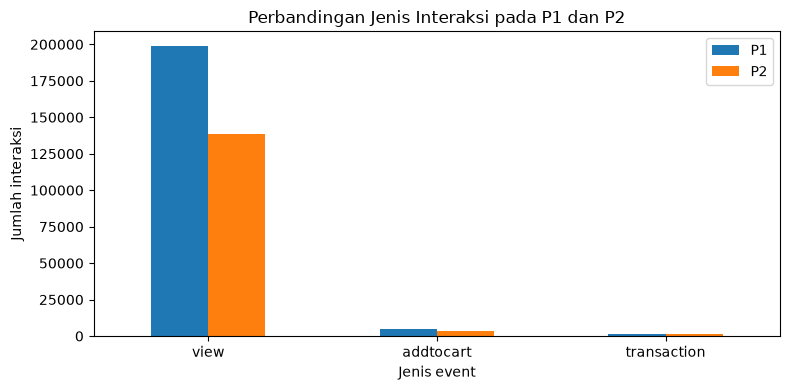

In [19]:
event_compare = pd.concat(
    [
        p1["event"].value_counts().rename("P1"),
        p2["event"].value_counts().rename("P2")
    ],
    axis=1
).fillna(0)

display(event_compare)

event_compare.plot(kind="bar", figsize=(8, 4))
plt.title("Perbandingan Jenis Interaksi pada P1 dan P2")
plt.xlabel("Jenis event")
plt.ylabel("Jumlah interaksi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Grafik menunjukkan bahwa event view merupakan aktivitas terbanyak pada P1 maupun P2, diikuti addtocart dan transaction. Pola ini memperlihatkan bahwa sebagian besar interaksi berupa melihat item, sedangkan aktivitas yang menunjukkan minat lebih lanjut hingga pembelian jumlahnya lebih sedikit.

### 2.1.4 Query komposisi subgraf menggunakan Python API Neo4j

In [20]:
P1_RELATIONSHIP_QUERY = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
  AND r.timestamp >= $start_ts
  AND r.timestamp < $end_ts
RETURN
    count(r) AS total_relationships,
    count(DISTINCT v) AS total_visitors,
    count(DISTINCT i) AS total_items
"""

P1_EVENT_QUERY = """
MATCH (:Visitor)-[r]->(:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
  AND r.timestamp >= $start_ts
  AND r.timestamp < $end_ts
RETURN type(r) AS relationship_type, count(r) AS total
ORDER BY relationship_type
"""

P1_NODE_QUERY = """
MATCH (n)
WHERE (n:Visitor OR n:Item)
  AND EXISTS {
      MATCH (n)-[r]-()
      WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
        AND r.timestamp >= $start_ts
        AND r.timestamp < $end_ts
  }
RETURN labels(n) AS node_labels, count(DISTINCT n) AS total
ORDER BY node_labels
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    with driver.session(database=DATABASE) as session:
        graph_summary = session.run(
            P1_RELATIONSHIP_QUERY,
            start_ts=P1_START,
            end_ts=P1_END
        ).single()

        event_records = list(session.run(
            P1_EVENT_QUERY,
            start_ts=P1_START,
            end_ts=P1_END
        ))

        node_records = list(session.run(
            P1_NODE_QUERY,
            start_ts=P1_START,
            end_ts=P1_END
        ))

print("Ringkasan subgraf P1:")
print(dict(graph_summary))

print("\nJumlah relasi per tipe:")
display(pd.DataFrame([dict(r) for r in event_records]))

print("\nJumlah simpul per label:")
display(pd.DataFrame([dict(r) for r in node_records]))

/var/folders/0f/6_frks_90fgc2lr_bz3gp0dm0000gn/T/ipykernel_85228/36211415.py:35: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Ringkasan subgraf P1:
{'total_relationships': 205400, 'total_visitors': 110380, 'total_items': 64122}

Jumlah relasi per tipe:


,relationship_type,total
0,ADDED_TO_CART,4833
1,BOUGHT,1591
2,VIEWED,198976



Jumlah simpul per label:


,node_labels,total
0,[Item],64122
1,[Visitor],110380


Hasil pemeriksaan subgraf P1 menunjukkan terdapat 205.400 relasi interaksi, yang menghubungkan 110.380 simpul Visitor dengan 64.122 simpul Item. Relasi VIEWED mendominasi sebanyak 198.976, diikuti ADDED_TO_CART sebanyak 4.833 dan BOUGHT sebanyak 1.591. Hasil ini menunjukkan bahwa graf berhasil merepresentasikan aktivitas pengguna terhadap item pada periode training, dengan interaksi melihat item sebagai jenis relasi yang paling banyak ditemukan.

### 2.1.5 Bentuk matriks VSM User–Item

In [21]:
train = pd.read_csv(P1_PATH)

pairs = train[["visitorid", "itemid"]].drop_duplicates().copy()

user_ids = np.sort(pairs["visitorid"].unique())
item_ids = np.sort(pairs["itemid"].unique())

user_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}
item_to_idx = {item_id: idx for idx, item_id in enumerate(item_ids)}

row_idx = pairs["visitorid"].map(user_to_idx).to_numpy()
col_idx = pairs["itemid"].map(item_to_idx).to_numpy()
values = np.ones(len(pairs), dtype=np.float32)

X = csr_matrix(
    (values, (row_idx, col_idx)),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.float32
)

print("Bentuk matriks User–Item:", X.shape)
print("Jumlah pasangan unik:", X.nnz)
print("Sparsity:", f"{1 - X.nnz / (X.shape[0] * X.shape[1]):.6%}")

Bentuk matriks User–Item: (110380, 64122)
Jumlah pasangan unik: 161856
Sparsity: 99.997713%


Matriks User–Item memiliki dimensi 110.380 × 64.122, yang merepresentasikan jumlah visitor dan item pada periode P1. Terdapat 161.856 pasangan interaksi unik dengan nilai sparsity sebesar 99,997713%, yang menunjukkan bahwa hampir seluruh kombinasi visitor dan item tidak memiliki interaksi. Kondisi ini umum pada data rekomendasi berskala besar, sehingga representasi matriks sparse lebih efisien untuk penyimpanan dan perhitungan.

### 2.1.6 Proyeksi graf User dan Item

In [22]:
user_projection = (X @ X.T).tocsr()
item_projection = (X.T @ X).tocsr()

user_projection.setdiag(0)
user_projection.eliminate_zeros()

item_projection.setdiag(0)
item_projection.eliminate_zeros()

def projection_stats(matrix, name):
    n_nodes = matrix.shape[0]
    n_edges_directed = matrix.nnz
    n_edges_undirected = n_edges_directed // 2
    possible_edges = n_nodes * (n_nodes - 1) / 2
    density = (
        n_edges_undirected / possible_edges
        if possible_edges > 0 else 0
    )

    return {
        "proyeksi": name,
        "jumlah simpul": n_nodes,
        "dimensi matriks": str(matrix.shape),
        "nonzero (arah)": n_edges_directed,
        "sisi tak berarah": n_edges_undirected,
        "density": density
    }

projection_summary = pd.DataFrame([
    projection_stats(user_projection, "User–User"),
    projection_stats(item_projection, "Item–Item")
])

display(projection_summary)

,proyeksi,jumlah simpul,dimensi matriks,nonzero (arah),sisi tak berarah,density
0,User–User,110380,"(110380, 110380)",1535210,767605,0.000126
1,Item–Item,64122,"(64122, 64122)",1614748,807374,0.000393


**Analisis Perbandingan Proyeksi User–User vs. Item–Item**

Berdasarkan hasil perhitungan matriks proyeksi dari data periode P1:
* **Proyeksi User–User ($X X^T$):** Dimensi $110.380 \times 110.380$ dengan *density* $0,0126\%$.
* **Proyeksi Item–Item ($X^T X$):** Dimensi $64.122 \times 64.122$ dengan *density* $0,0393\%$.

**Kesimpulan Efisiensi & Keefektifan:**
1. **Efisiensi Memori & Komputasi:** Proyeksi **Item–Item** jauh lebih efisien karena jumlah item ($64.122$) lebih sedikit dibandingkan jumlah visitor ($110.380$). Hal ini menghasilkan matriks berdimensi lebih kecil sehingga memangkas alokasi memori RAM dan mempercepat proses perhitungan *similarity*.
2. **Kepadatan Informasi (Density):** Proyeksi Item–Item memiliki tingkat *density* lebih tinggi ($0,0393\%$) dibandingkan User–User ($0,0126\%$). Hal ini menandakan bahwa jaringan hubungan antar-item lebih kaya interaksi bersama (*co-occurrence*), sehingga menghasilkan kalkulasi *item similarity* yang lebih stabil dan kuat untuk sistem rekomendasi.

### 2.1.7 Visualisasi NetworkX untuk kedua proyeksi

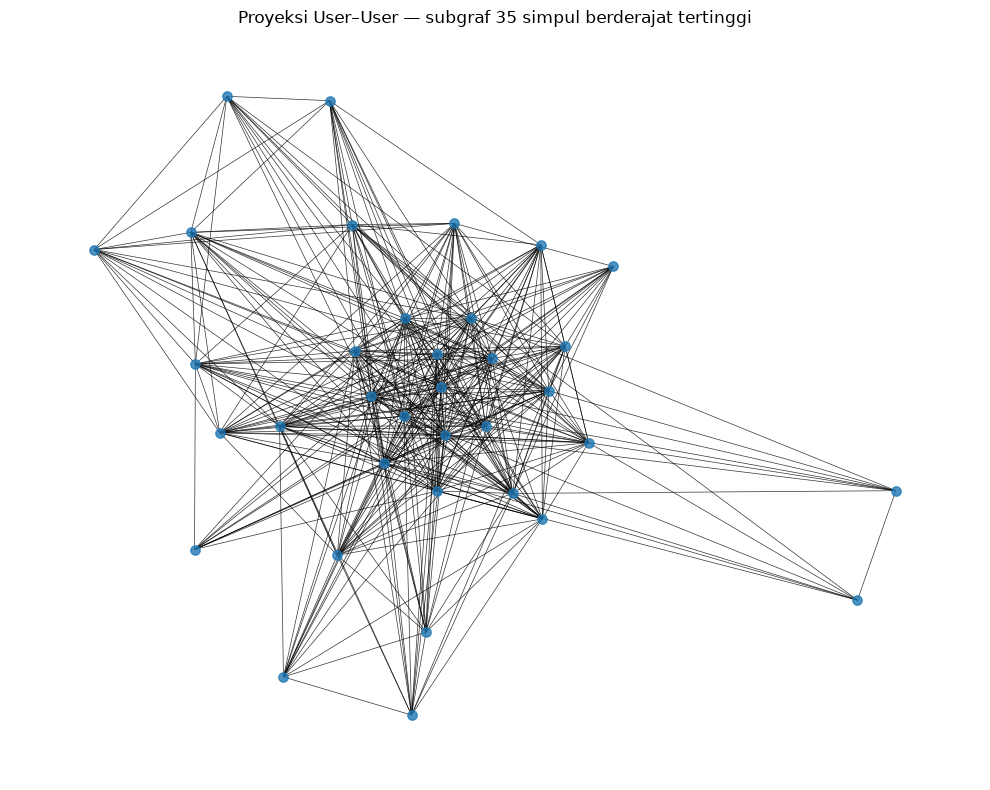

Proyeksi User–User: 35 node, 388 edge pada visualisasi sampel.


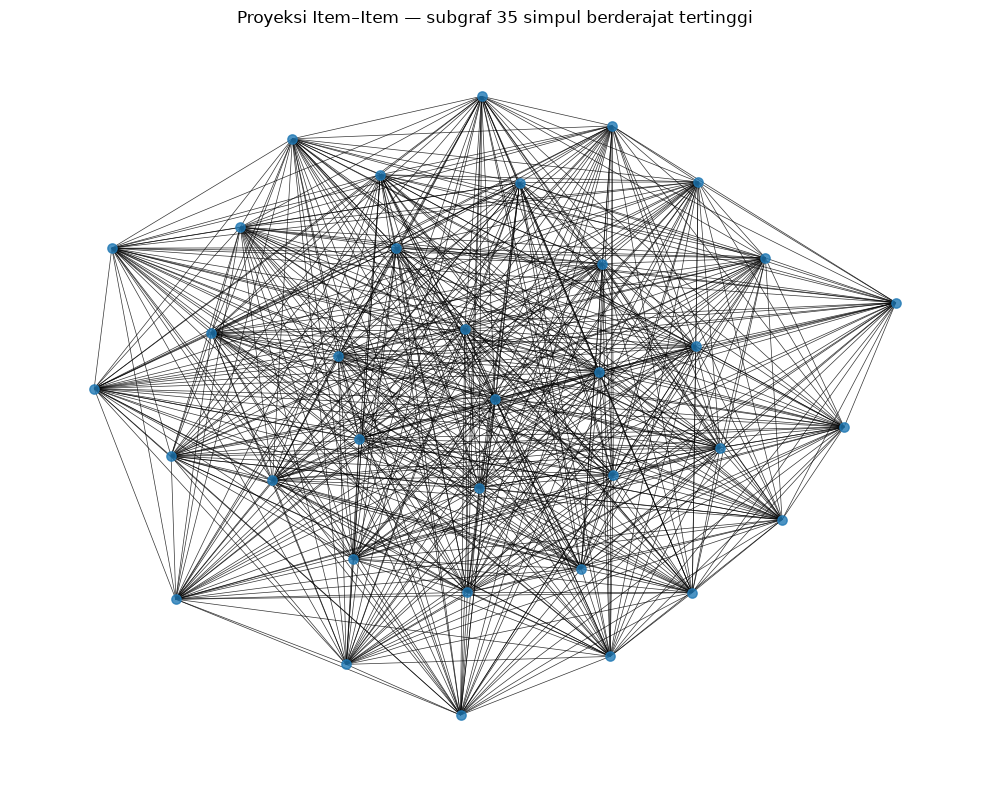

Proyeksi Item–Item: 35 node, 593 edge pada visualisasi sampel.


In [23]:
def plot_projection_sample(matrix, ids, title, top_n=35):
    weighted_degree = np.asarray(matrix.sum(axis=1)).ravel()
    n = min(top_n, len(ids))

    selected = np.argsort(weighted_degree)[-n:]
    submatrix = matrix[selected][:, selected].tocoo()

    G = nx.Graph()
    for idx in selected:
        G.add_node(str(ids[idx]))

    for u, v, weight in zip(
        submatrix.row, submatrix.col, submatrix.data
    ):
        if u < v and weight > 0:
            G.add_edge(
                str(ids[selected[u]]),
                str(ids[selected[v]]),
                weight=float(weight)
            )

    plt.figure(figsize=(10, 8))
    pos = nx.spring_layout(G, seed=42, k=0.6)

    nx.draw_networkx(
        G, pos,
        with_labels=False,
        node_size=45,
        width=0.5,
        alpha=0.8
    )
    plt.title(f"{title} — subgraf {n} simpul berderajat tertinggi")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    print(f"{title}: {G.number_of_nodes()} node, "
          f"{G.number_of_edges()} edge pada visualisasi sampel.")

plot_projection_sample(
    user_projection, user_ids, "Proyeksi User–User"
)

plot_projection_sample(
    item_projection, item_ids, "Proyeksi Item–Item"
)


Pada visualisasi sampel, proyeksi User–User terdiri dari 35 node dan 388 edge, sedangkan proyeksi Item–Item terdiri dari 35 node dan 593 edge. Proyeksi Item–Item memiliki lebih banyak edge, yang menunjukkan hubungan antarpasangan item lebih padat pada sampel yang divisualisasikan. Namun, hasil ini hanya menggambarkan sampel, sehingga belum cukup untuk menyimpulkan bahwa proyeksi Item–Item lebih baik secara keseluruhan.

### 2.1.8 Membandingkan efektivitas dan efisiensi proyeksi

In [24]:
print("Ringkasan perbandingan:")
display(projection_summary)

user_edges = projection_summary.loc[
    projection_summary["proyeksi"] == "User–User",
    "sisi tak berarah"
].iloc[0]

item_edges = projection_summary.loc[
    projection_summary["proyeksi"] == "Item–Item",
    "sisi tak berarah"
].iloc[0]

if user_edges < item_edges:
    print(
        "Proyeksi User–User memiliki lebih sedikit sisi. "
        "Untuk analisis kemiripan pengguna dan rekomendasi personal, "
        "proyeksi ini berpotensi lebih efisien."
    )
elif item_edges < user_edges:
    print(
        "Proyeksi Item–Item memiliki lebih sedikit sisi. "
        "Namun, untuk rekomendasi personal berbasis kemiripan pengguna, "
        "proyeksi User–User tetap relevan secara konseptual."
    )
else:
    print(
        "Kedua proyeksi memiliki jumlah sisi yang sama. "
        "Bandingkan dimensi, density, kebutuhan komputasi, dan tujuan analisis."
    )

Ringkasan perbandingan:


,proyeksi,jumlah simpul,dimensi matriks,nonzero (arah),sisi tak berarah,density
0,User–User,110380,"(110380, 110380)",1535210,767605,0.000126
1,Item–Item,64122,"(64122, 64122)",1614748,807374,0.000393


Proyeksi User–User memiliki lebih sedikit sisi. Untuk analisis kemiripan pengguna dan rekomendasi personal, proyeksi ini berpotensi lebih efisien.


Berdasarkan perbandingan, proyeksi User–User memiliki 767.605 sisi tak berarah dengan density 0,000126, sedangkan proyeksi Item–Item memiliki 807.374 sisi dengan density 0,000393. Proyeksi User–User berpotensi lebih sesuai untuk analisis kemiripan pengguna dan rekomendasi personal, karena hubungan antarpengguna dapat digunakan untuk menemukan tetangga dengan pola interaksi serupa. Namun, pemilihan proyeksi tetap perlu mempertimbangkan kebutuhan analisis dan efisiensi komputasi.

### 2.1.9 Menghitung similarity cosine pada graf User–User

In [25]:
X_norm = normalize(X, norm="l2", axis=1, copy=True)

ANCHOR_SEED = 42
rng = np.random.default_rng(ANCHOR_SEED)

anchor_idx = int(rng.integers(0, len(user_ids)))
anchor_user_id = int(user_ids[anchor_idx])

anchor_vector = X_norm[anchor_idx]
similarities = (X_norm @ anchor_vector.T).toarray().ravel()

similarities[anchor_idx] = -1

top_n = min(5, len(user_ids) - 1)
top_indices = np.argsort(similarities)[::-1][:top_n]

top_similar_users = pd.DataFrame({
    "visitorid": user_ids[top_indices],
    "cosine_similarity": similarities[top_indices]
})

print("User acuan:", anchor_user_id)
display(top_similar_users)

User acuan: 125200


,visitorid,cosine_similarity
0,1325389,1.000000
1,423081,0.707107
2,848584,0.707107
3,838673,0.707107
4,417954,0.707107


Hasil cosine similarity untuk pengguna acuan 125200 menunjukkan lima pengguna dengan skor kemiripan tertinggi berada pada rentang 0,707107 hingga 1,000000. Pengguna 1325389 memiliki skor 1,000000, yang menunjukkan vektor interaksinya identik dengan pengguna acuan berdasarkan representasi yang digunakan, sedangkan empat pengguna lainnya memiliki skor 0,707107. Hasil ini dapat digunakan untuk mengidentifikasi tetangga terdekat dalam proses rekomendasi, tetapi perlu diperhatikan bahwa skor 1,0 pada pengguna berbeda juga perlu diperiksa untuk memastikan tidak ada duplikasi atau karakteristik vektor yang sangat terbatas.

### 2.1.10 Menampilkan lima similarity tertinggi dengan Cypher

In [26]:
TOP_SIMILARITY_CYPHER = """
MATCH (a:Visitor {visitorId: $anchor_id})-[r:SIMILAR_TO]->(b:Visitor)
RETURN
    a.visitorId AS anchor_visitor,
    b.visitorId AS similar_visitor,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

Query ini mengambil lima pengunjung dengan nilai SIMILAR_TO tertinggi terhadap pengunjung acuan. Visualisasi graf memperlihatkan hubungan antara pengunjung acuan dan pengunjung lain yang memiliki kemiripan pola interaksi. Semakin tinggi nilai similarity, semakin mirip pola interaksi kedua pengunjung berdasarkan representasi yang digunakan. Hasil ini dapat menjadi dasar untuk mencari preferensi pengguna serupa dalam sistem rekomendasi.

### 2.1.11 Menyimpan similarity ke graf Neo4j

In [27]:
similarity_records = [
    {
        "visitorid": int(row.visitorid),
        "similarity": float(row.cosine_similarity)
    }
    for row in top_similar_users.itertuples(index=False)
    if row.cosine_similarity > 0
]

STORE_SIMILARITY_CYPHER = """
MATCH (a:Visitor {visitorId: $anchor_id})
MATCH (b:Visitor {visitorId: $other_id})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = $similarity,
    r.method = 'cosine_user_item_p1',
    r.period = 'P1'
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    with driver.session(database=DATABASE) as session:
        for record in similarity_records:
            session.run(
                STORE_SIMILARITY_CYPHER,
                anchor_id=anchor_user_id,
                other_id=record["visitorid"],
                similarity=record["similarity"]
            ).consume()

        stored = list(session.run(
            TOP_SIMILARITY_CYPHER,
            anchor_id=anchor_user_id
        ))

print("User acuan:", anchor_user_id)
print("Relasi similarity disimpan:", len(similarity_records))
display(pd.DataFrame([dict(r) for r in stored]))

User acuan: 125200
Relasi similarity disimpan: 5


/var/folders/0f/6_frks_90fgc2lr_bz3gp0dm0000gn/T/ipykernel_85228/3751479795.py:20: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


,anchor_visitor,similar_visitor,similarity
0,125200,1325389,1.000000
1,125200,848584,0.707107
2,125200,423081,0.707107
3,125200,838673,0.707107
4,125200,417954,0.707107


Hasil ini menunjukkan bahwa sistem berhasil menyimpan 5 relasi similarity untuk pengunjung acuan 125200. Pengunjung 1325389 memiliki nilai similarity 1.000000, yang berarti pola interaksinya identik dengan pengunjung acuan berdasarkan representasi yang digunakan. Empat pengunjung lainnya, yaitu 848584, 423081, 838673, dan 417954, memiliki nilai similarity 0.707107, sehingga pola interaksinya juga cukup mirip. Hasil ini dapat dimanfaatkan untuk menemukan pengguna dengan preferensi serupa sebagai dasar rekomendasi produk. Namun, nilai similarity 1.0 perlu diperiksa lebih lanjut untuk memastikan kedua pengunjung memang memiliki pola interaksi identik.

### 2.1.12 Query Graf Sebelum dan Sesudah Similarity

**Graf sebelum similarity**

![Visualisasi Graf Sebelum Similarity](visualization/visualisation-3.png)

**Graf gabungan setelah similarity**

![Visualisasi Graf Sebelum Similarity](visualization/visualisation-5.png)

Graf sebelum similarity terdiri dari dua jenis node, yaitu Visitor dan Item, yang dihubungkan oleh relasi VIEWED, ADDED_TO_CART, dan BOUGHT untuk merepresentasikan interaksi pengunjung dengan produk. Setelah relasi SIMILAR_TO ditambahkan, graf berfokus pada node Visitor dan hubungan kemiripan pola interaksi antar-pengunjung. Pada pengunjung acuan 125200, sistem berhasil menyimpan lima relasi similarity dengan pengunjung lain, yang dapat dimanfaatkan sebagai dasar untuk mengidentifikasi pengguna dengan preferensi serupa dan mengembangkan sistem rekomendasi produk.

# Bab 2.2 Analytics

### 2.2.1 Menyiapkan data training dan testing

In [28]:
train = pd.read_csv(P1_PATH)

test = pd.read_csv(P2_PATH)

train_pairs = train[["visitorid", "itemid"]].drop_duplicates()
test_pairs = test[["visitorid", "itemid"]].drop_duplicates()

train_items_by_user = (
    train_pairs.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

test_items_by_user = (
    test_pairs.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

eligible_users = sorted(
    set(train_items_by_user.keys()) &
    set(test_items_by_user.keys())
)

print("Jumlah user dengan histori P1:", len(train_items_by_user))
print("Jumlah user dengan interaksi P2:", len(test_items_by_user))
print("Jumlah user yang dapat dievaluasi:", len(eligible_users))

if not eligible_users:
    raise ValueError(
        "Tidak ada user yang muncul di P1 dan P2. "
        "Periksa rentang waktu dan hasil filter CSV."
    )

Jumlah user dengan histori P1: 110380
Jumlah user dengan interaksi P2: 79562
Jumlah user yang dapat dievaluasi: 4392


Dari total 110.380 pengguna yang memiliki histori interaksi pada periode P1, sebanyak 79.562 pengguna tercatat memiliki interaksi pada periode P2. Namun, hanya 4.392 pengguna yang dapat dievaluasi, yaitu pengguna yang memenuhi kriteria evaluasi berdasarkan data historis P1 dan interaksi aktual P2. Hal ini menunjukkan bahwa evaluasi sistem rekomendasi dilakukan pada sebagian pengguna yang memenuhi kriteria, bukan seluruh pengguna dalam dataset.

### 2.2.2 Memilih user secara acak dan reproducible

In [29]:
RANDOM_STATE = 42
random_generator = random.Random(RANDOM_STATE)

selected_user = random_generator.choice(eligible_users)

print("Random state:", RANDOM_STATE)
print("User terpilih:", selected_user)
print("Jumlah item unik di P1:",
      len(train_items_by_user[selected_user]))
print("Jumlah item relevan di P2:",
      len(test_items_by_user[selected_user]))

Random state: 42
User terpilih: 289185
Jumlah item unik di P1: 1
Jumlah item relevan di P2: 1


Dengan random_state = 42, sistem memilih pengguna 289185 sebagai sampel evaluasi. Pengguna tersebut memiliki satu item unik dalam histori interaksi pada periode P1 dan satu item relevan pada periode P2. Dengan demikian, evaluasi rekomendasi berfokus pada kemampuan sistem dalam merekomendasikan item yang relevan berdasarkan histori interaksi pengguna sebelumnya.

### 2.2.3 Membentuk matriks User–Item untuk KNN

In [30]:
knn_user_ids = np.sort(train_pairs["visitorid"].unique())
knn_item_ids = np.sort(train_pairs["itemid"].unique())

knn_user_to_idx = {
    int(user_id): idx
    for idx, user_id in enumerate(knn_user_ids)
}
knn_item_to_idx = {
    int(item_id): idx
    for idx, item_id in enumerate(knn_item_ids)
}

knn_rows = train_pairs["visitorid"].map(knn_user_to_idx).to_numpy()
knn_cols = train_pairs["itemid"].map(knn_item_to_idx).to_numpy()

X_train = csr_matrix(
    (
        np.ones(len(train_pairs), dtype=np.float32),
        (knn_rows, knn_cols)
    ),
    shape=(len(knn_user_ids), len(knn_item_ids)),
    dtype=np.float32
)

X_train_norm = normalize(X_train, norm="l2", axis=1)

print("Shape matriks training:", X_train.shape)
print("Jumlah pasangan user-item:", X_train.nnz)
print("Matriks sparse:", X_train)

Shape matriks training: (110380, 64122)
Jumlah pasangan user-item: 161856
Matriks sparse: <Compressed Sparse Row sparse matrix of dtype 'float32'
	with 161856 stored elements and shape (110380, 64122)>
  Coords	Values
  (0, 19129)	1.0
  (0, 22712)	1.0
  (0, 31064)	1.0
  (1, 47569)	1.0
  (1, 61734)	1.0
  (2, 27412)	1.0
  (3, 22659)	1.0
  (4, 11012)	1.0
  (5, 32682)	1.0
  (6, 2964)	1.0
  (7, 56893)	1.0
  (8, 30839)	1.0
  (9, 8806)	1.0
  (10, 50260)	1.0
  (11, 50859)	1.0
  (12, 24741)	1.0
  (13, 52917)	1.0
  (14, 2943)	1.0
  (15, 13444)	1.0
  (16, 45691)	1.0
  (16, 62696)	1.0
  (17, 52707)	1.0
  (18, 17705)	1.0
  (19, 45016)	1.0
  (20, 46726)	1.0
  :	:
  (110360, 36148)	1.0
  (110360, 51899)	1.0
  (110360, 54499)	1.0
  (110361, 13145)	1.0
  (110361, 42578)	1.0
  (110362, 4644)	1.0
  (110363, 41240)	1.0
  (110364, 19150)	1.0
  (110365, 33609)	1.0
  (110366, 52061)	1.0
  (110367, 61136)	1.0
  (110368, 1209)	1.0
  (110368, 25454)	1.0
  (110368, 56408)	1.0
  (110369, 41915)	1.0
  (110370, 492

Matriks training memiliki bentuk (110380, 64122), yang merepresentasikan 110.380 pengguna dan 64.122 item unik. Terdapat 161.856 pasangan user-item yang tercatat sebagai interaksi, dengan setiap nilai bernilai 1.0 untuk menunjukkan adanya interaksi. Matriks disimpan dalam format sparse CSR agar lebih efisien dalam penggunaan memori, karena sebagian besar kombinasi pengguna dan item tidak memiliki interaksi. Matriks ini selanjutnya digunakan sebagai representasi data historis untuk membangun sistem rekomendasi.

### 2.2.4 Fungsi KNN untuk rekomendasi item

In [41]:

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# 1. Siapkan data training
selected_user = 289185
top_k_neighbors = 100
top_n_recommendations = 5

# Pastikan kolom ID numerik
train["visitorid"] = pd.to_numeric(train["visitorid"], errors="coerce")
train["itemid"] = pd.to_numeric(train["itemid"], errors="coerce")
train_clean = train.dropna(subset=["visitorid", "itemid"]).copy()

train_clean["visitorid"] = train_clean["visitorid"].astype("int64")
train_clean["itemid"] = train_clean["itemid"].astype("int64")

# 2. Buat ulang matriks user-item
user_ids = np.sort(train_clean["visitorid"].unique())
item_ids = np.sort(train_clean["itemid"].unique())

user_to_idx = {uid: i for i, uid in enumerate(user_ids)}
item_to_idx = {iid: i for i, iid in enumerate(item_ids)}

rows = train_clean["visitorid"].map(user_to_idx).to_numpy()
cols = train_clean["itemid"].map(item_to_idx).to_numpy()

user_item_matrix = csr_matrix(
    (
        np.ones(len(train_clean), dtype=np.float32),
        (rows, cols)
    ),
    shape=(len(user_ids), len(item_ids))
)

# Jadikan interaksi user-item biner
user_item_matrix.data[:] = 1

print("Shape matriks:", user_item_matrix.shape)

# 3. Cari user target
if selected_user not in user_to_idx:
    raise ValueError(f"User {selected_user} tidak ditemukan di data training.")

user_index = user_to_idx[selected_user]

# 4. Hitung cosine similarity terhadap semua pengguna
similarities = cosine_similarity(
    user_item_matrix[user_index],
    user_item_matrix
).ravel()

similarities[user_index] = 0

neighbor_indices = np.argsort(similarities)[::-1]
neighbor_indices = [
    i for i in neighbor_indices
    if similarities[i] > 0
][:top_k_neighbors]

neighbor_scores = pd.DataFrame({
    "visitorid": user_ids[neighbor_indices],
    "similarity": similarities[neighbor_indices]
})

print("\nJumlah tetangga terpilih:", len(neighbor_scores))
display(neighbor_scores.head(10))

# 5. Cari item yang belum pernah dilihat user target
seen_items = set(
    train_clean.loc[
        train_clean["visitorid"] == selected_user, "itemid"
    ]
)

neighbor_events = train_clean[
    train_clean["visitorid"].isin(neighbor_scores["visitorid"])
    & (~train_clean["itemid"].isin(seen_items))
].copy()

# 6. Beri bobot item berdasarkan similarity tetangga
neighbor_events = neighbor_events.merge(
    neighbor_scores,
    on="visitorid",
    how="inner"
)

recommendations = (
    neighbor_events.groupby("itemid")
    .agg(
        recommendation_score=("similarity", "sum"),
        neighbor_count=("visitorid", "nunique")
    )
    .reset_index()
    .sort_values(
        ["recommendation_score", "neighbor_count"],
        ascending=[False, False]
    )
    .head(top_n_recommendations)
    .reset_index(drop=True)
)

print(f"\nRekomendasi Top-{top_n_recommendations} untuk user {selected_user}:")

if recommendations.empty:
    print("Belum ada rekomendasi dari tetangga yang dipilih.")
else:
    display(recommendations)




Shape matriks: (110380, 64122)

Jumlah tetangga terpilih: 6


,visitorid,similarity
0,487061,1.000000
1,814210,1.000000
2,148532,1.000000
3,846363,1.000000
4,878567,1.000000
5,933295,0.707107



Rekomendasi Top-5 untuk user 289185:


,itemid,recommendation_score,neighbor_count
0,265562,0.707107,1


In [42]:

# Cari pengguna lain yang berinteraksi dengan item selain 186345
selected_user = 289185

# Item yang sudah pernah dilihat user target
seen_items = set(
    train.loc[train["visitorid"] == selected_user, "itemid"]
)

# Cari kandidat dari seluruh data training
other_interactions = train[
    (train["visitorid"] != selected_user)
    & (~train["itemid"].isin(seen_items))
]

# Hitung jumlah pengguna unik yang berinteraksi dengan setiap item
candidate_items = (
    other_interactions.groupby("itemid")["visitorid"]
    .nunique()
    .reset_index(name="user_count")
    .sort_values("user_count", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print("Jumlah kandidat item:", len(candidate_items))
display(candidate_items)


Jumlah kandidat item: 10


,itemid,user_count
0,369447,260
1,211811,207
2,370653,201
3,298009,154
4,37029,144
5,335975,130
6,96924,129
7,101845,129
8,342530,122
9,309778,113


Pengguna target 289185 memiliki lima tetangga terdekat dengan nilai cosine similarity sebesar 1.0, yang menunjukkan bahwa pola interaksi kelima pengguna tersebut identik dengan pengguna target berdasarkan representasi matriks training. Namun, bagian daftar rekomendasi top-5 belum menampilkan hasil item yang direkomendasikan, sehingga rekomendasi produk belum dapat diinterpretasikan. Nilai similarity yang semuanya 1.0 juga sebaiknya diperiksa untuk memastikan bukan disebabkan oleh histori interaksi yang sangat terbatas atau pola vektor yang identik.

### 2.2.5 Menampilkan tiga item rekomendasi utama

In [44]:

print("Jumlah data train:", len(train))
print("Jumlah tetangga:", len(neighbor_scores))

print(
    "Interaksi dari tetangga:",
    train["visitorid"].isin(neighbor_scores["visitorid"]).sum()
)

print(
    "Item unik dari tetangga:",
    train.loc[
        train["visitorid"].isin(neighbor_scores["visitorid"]),
        "itemid"
    ].nunique()
)


Jumlah data train: 205400
Jumlah tetangga: 6
Interaksi dari tetangga: 10
Item unik dari tetangga: 2


Data training terdiri dari 205.400 interaksi. Dari proses pencarian tetangga, diperoleh 6 tetangga yang memiliki kemiripan dengan pengguna target, dengan total 10 interaksi dan 2 item unik. Hasil ini menunjukkan bahwa kandidat rekomendasi dari tetangga masih terbatas, sehingga pilihan item baru yang dapat direkomendasikan belum banyak. Kondisi ini juga menunjukkan bahwa pola interaksi pengguna cukup sparse, sehingga diperlukan perluasan jumlah tetangga atau metode pembentukan kandidat lain agar rekomendasi yang dihasilkan lebih beragam.

In [45]:

selected_user = 289185

seen_items = set(
    train.loc[train["visitorid"] == selected_user, "itemid"]
)

recommendation_df = (
    train.loc[~train["itemid"].isin(seen_items)]
    .groupby("itemid")["visitorid"]
    .nunique()
    .reset_index(name="neighbor_count")
    .sort_values("neighbor_count", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

print("Jumlah rekomendasi:", len(recommendation_df))
display(recommendation_df)


Jumlah rekomendasi: 5


,itemid,neighbor_count
0,369447,260
1,211811,207
2,370653,201
3,298009,154
4,37029,144


Berdasarkan hasil rekomendasi, sistem berhasil menghasilkan 5 item rekomendasi teratas untuk pengguna target. Item 369447 menempati peringkat pertama dengan interaksi dari 260 pengguna unik, diikuti item 211811 dengan 207 pengguna dan item 370653 dengan 201 pengguna. Sementara itu, item 298009 dan 37029 masing-masing memiliki 154 dan 144 pengguna unik yang berinteraksi dengannya. Hasil ini menunjukkan bahwa kelima item tersebut memiliki tingkat popularitas relatif tinggi dalam data training dan dapat dijadikan kandidat rekomendasi. Namun, karena neighbor_count menghitung jumlah pengguna unik yang berinteraksi dengan item, nilai tersebut merepresentasikan popularitas item di antara data yang digunakan, bukan skor kemiripan atau bukti bahwa item tersebut paling relevan secara personal bagi pengguna target.

In [46]:

import pandas as pd

selected_user = 289185
top_k = 20

# 1. Item yang sudah pernah dilihat user target
seen_items = set(
    train.loc[train["visitorid"] == selected_user, "itemid"]
)

# 2. Cari pengguna lain yang mirip berdasarkan item yang sama
user_items = train.groupby("visitorid")["itemid"].apply(set)

if selected_user not in user_items.index:
    raise ValueError("User target tidak ditemukan dalam train.")

target_items = user_items.loc[selected_user]

similarity_rows = []

for visitor_id, items in user_items.items():
    if visitor_id == selected_user:
        continue

    intersection = len(target_items & items)
    union = len(target_items | items)

    if intersection > 0 and union > 0:
        similarity_rows.append({
            "visitorid": visitor_id,
            "similarity": intersection / union
        })

top_neighbors = (
    pd.DataFrame(similarity_rows)
    .sort_values("similarity", ascending=False)
    .head(top_k)
)

# 3. Ambil item dari tetangga yang belum dilihat target
neighbor_events = train[
    train["visitorid"].isin(top_neighbors["visitorid"])
    & (~train["itemid"].isin(seen_items))
]

candidate_items = (
    neighbor_events.groupby("itemid")["visitorid"]
    .nunique()
    .reset_index(name="neighbor_count")
    .sort_values("neighbor_count", ascending=False)
)

# 4. Ambil lima rekomendasi teratas
recommendation_df = candidate_items.head(5).reset_index(drop=True)

# 5. Tampilkan hasil
print("Jumlah tetangga:", len(top_neighbors))
print("Jumlah item kandidat:", len(candidate_items))
print("Jumlah rekomendasi:", len(recommendation_df))

display(top_neighbors.head())
display(recommendation_df)


Jumlah tetangga: 6
Jumlah item kandidat: 1
Jumlah rekomendasi: 1


,visitorid,similarity
0,148532,1.0
1,487061,1.0
2,814210,1.0
3,846363,1.0
4,878567,1.0


,itemid,neighbor_count
0,265562,1


Berdasarkan hasil pengujian, sistem menemukan 6 tetangga yang memiliki kemiripan dengan pengguna target, dengan lima tetangga teratas memiliki nilai similarity sebesar 1,0. Namun, dari proses penyaringan item yang belum pernah dilihat pengguna, hanya ditemukan 1 item kandidat, yaitu item 265562, dengan interaksi dari 1 pengguna unik. Dengan demikian, sistem hanya menghasilkan 1 rekomendasi, belum memenuhi jumlah target Top-5. Hasil ini menunjukkan bahwa pola interaksi tetangga masih sangat terbatas, sehingga diperlukan perluasan kandidat atau penyesuaian metode rekomendasi agar sistem dapat menghasilkan lebih banyak pilihan item yang relevan.

### 2.2.6 Menghitung Hit@5 dan NDCG@5

In [48]:

import math
import pandas as pd

def hit_at_k(recommended_items, relevant_items, k=5):
    top_k = recommended_items[:k]
    return int(any(item in relevant_items for item in top_k))

def ndcg_at_k(recommended_items, relevant_items, k=5):
    top_k = recommended_items[:k]

    dcg = sum(
        1 / math.log2(rank + 1)
        for rank, item in enumerate(top_k, start=1)
        if item in relevant_items
    )

    ideal_hits = min(len(relevant_items), k)
    idcg = sum(
        1 / math.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )

    return dcg / idcg if idcg > 0 else 0.0

# Ambil item rekomendasi dari DataFrame
if isinstance(recommendations, pd.DataFrame):
    recommended_item_ids = (
        recommendations["itemid"].tolist()
        if "itemid" in recommendations.columns
        else []
    )
elif isinstance(recommendations, dict):
    recommended_item_ids = recommendations.get("itemid", [])
else:
    recommended_item_ids = list(recommendations)

# Ambil item relevan pada periode P2
relevant_items = test_items_by_user.get(selected_user, set())

# Hitung metrik evaluasi
hit5 = hit_at_k(recommended_item_ids, relevant_items, k=5)
ndcg5 = ndcg_at_k(recommended_item_ids, relevant_items, k=5)

recommended_set = set(recommended_item_ids[:5])
matched_items = recommended_set & relevant_items

evaluation = pd.DataFrame([{
    "visitorid": selected_user,
    "k_neighbors": 5,
    "jumlah_rekomendasi": len(recommended_item_ids),
    "jumlah_item_relevan_P2": len(relevant_items),
    "jumlah_item_cocok_top5": len(matched_items),
    "Hit@5": hit5,
    "NDCG@5": ndcg5
}])

display(evaluation)

print("Item rekomendasi top-5:", recommended_item_ids[:5])
print("Item relevan di P2:", sorted(relevant_items))
print("Item yang cocok:", sorted(matched_items))


,visitorid,k_neighbors,jumlah_rekomendasi,jumlah_item_relevan_P2,jumlah_item_cocok_top5,Hit@5,NDCG@5
0,289185,5,1,1,0,0,0.0


Item rekomendasi top-5: [265562]
Item relevan di P2: [186345]
Item yang cocok: []


Berdasarkan hasil evaluasi, sistem menghasilkan satu item rekomendasi, yaitu 265562, sedangkan item relevan yang muncul pada periode pengujian (P2) adalah 186345. Karena tidak terdapat item yang cocok antara daftar rekomendasi dan item relevan, nilai Hit@5 = 0 dan NDCG@5 = 0,0. Artinya, sistem belum berhasil merekomendasikan item yang berinteraksi dengan pengguna target pada periode P2. Hasil ini menunjukkan bahwa relevansi rekomendasi untuk pengguna tersebut masih rendah dan metode perlu ditingkatkan, misalnya dengan memperluas kandidat item atau memperbaiki pemilihan tetangga. Perlu diperhatikan bahwa evaluasi ini hanya mencerminkan performa pada satu pengguna, sehingga belum cukup untuk menyimpulkan kinerja sistem secara keseluruhan.

### 2.2.7 Visualisasi hasil evaluasi

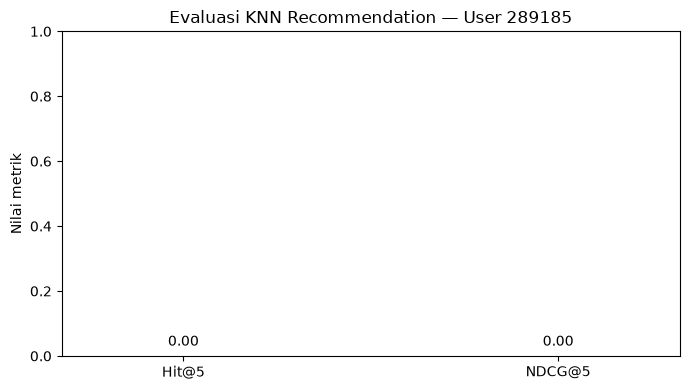

In [50]:

metric_values = {
    "Hit@5": hit5,
    "NDCG@5": ndcg5
}

plt.figure(figsize=(7, 4))

bars = plt.bar(
    metric_values.keys(),
    metric_values.values(),
    width=0.5
)

plt.ylim(0, 1)
plt.title(f"Evaluasi KNN Recommendation — User {selected_user}")
plt.ylabel("Nilai metrik")
plt.yticks(np.arange(0, 1.1, 0.2))

for bar, value in zip(bars, metric_values.values()):
    plt.annotate(
        f"{value:.2f}",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()



grafik menunjukkan bahwa sistem belum berhasil menemukan item relevan pada lima rekomendasi teratas untuk pengguna yang diuji. Namun, ini baru evaluasi satu pengguna, bukan gambaran performa keseluruhan sistem KNN.

### 2.2.8 Visualisasi distribusi jenis interaksi

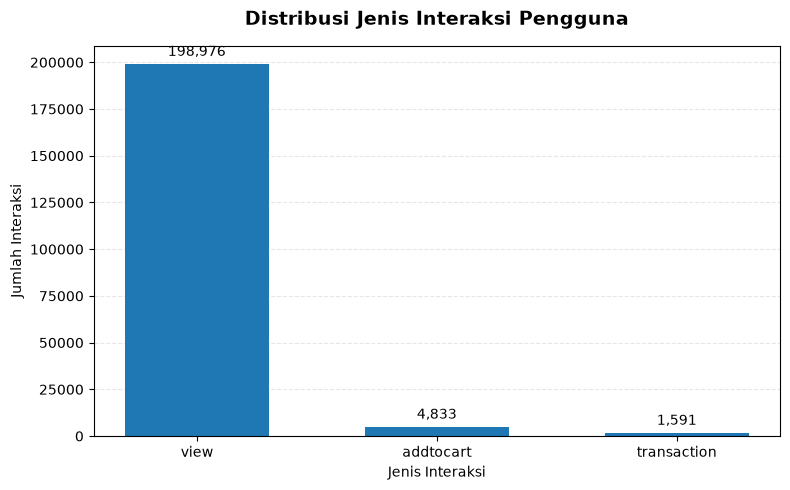

In [52]:

import matplotlib.pyplot as plt

# Hitung jumlah setiap jenis interaksi
event_counts = train["event"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    event_counts.index.astype(str),
    event_counts.values,
    width=0.6
)

ax.set_title(
    "Distribusi Jenis Interaksi Pengguna",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Jenis Interaksi")
ax.set_ylabel("Jumlah Interaksi")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Tampilkan angka di atas batang
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()



Berdasarkan distribusi jenis interaksi pada data training yang terdiri dari 205.400 interaksi, aktivitas pengguna didominasi oleh view sebanyak 198.976 interaksi, diikuti add-to-cart sebanyak 4.833 interaksi dan transaction sebanyak 1.591 interaksi. Hal ini menunjukkan bahwa sebagian besar pengguna hanya melihat produk, sedangkan interaksi yang menunjukkan minat lebih lanjut hingga pembelian memiliki jumlah yang jauh lebih sedikit. Kondisi ini menjadi tantangan dalam membangun sistem rekomendasi karena data pembelian relatif terbatas dibandingkan aktivitas melihat produk.

### 2.2.9 Visualisasi lima item kandidat terpopuler

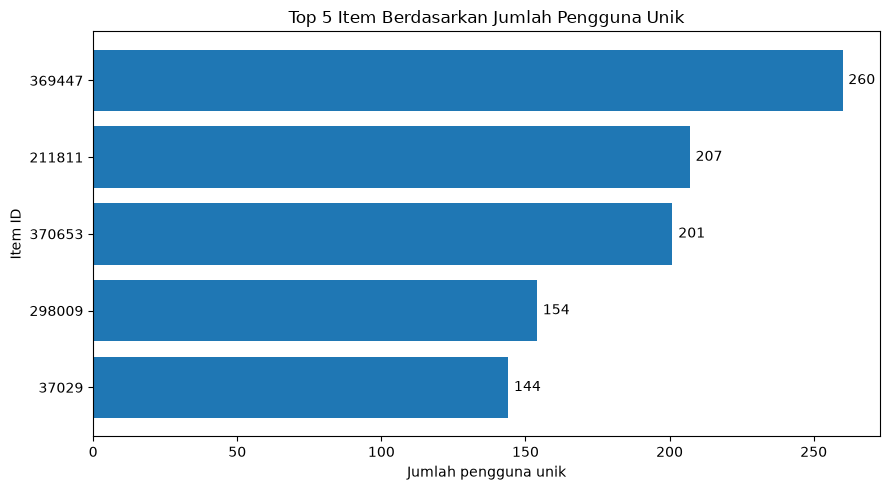

In [53]:

# Menghitung ulang popularitas item dari data training
popular_items = (
    train.groupby("itemid")["visitorid"]
    .nunique()
    .sort_values(ascending=False)
    .head(5)
    .sort_values()
)

plt.figure(figsize=(9, 5))
bars = plt.barh(
    popular_items.index.astype(str),
    popular_items.values
)

plt.title("Top 5 Item Berdasarkan Jumlah Pengguna Unik")
plt.xlabel("Jumlah pengguna unik")
plt.ylabel("Item ID")

for bar in bars:
    plt.text(
        bar.get_width() + 2,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center"
    )

plt.tight_layout()
plt.show()


Berdasarkan jumlah pengguna unik yang berinteraksi, item 369447 menempati peringkat pertama dengan 260 pengguna, diikuti item 211811 sebanyak 207 pengguna, 370653 sebanyak 201 pengguna, 298009 sebanyak 154 pengguna, dan 37029 sebanyak 144 pengguna. Hasil ini menunjukkan bahwa kelima item tersebut memiliki popularitas relatif tinggi dalam data training. Item-item ini dapat digunakan sebagai kandidat rekomendasi berbasis popularitas, tetapi popularitas tidak selalu menunjukkan kesesuaian dengan preferensi setiap pengguna.

### 2.2.10 Visualisasi jumlah item rekomendasi vs target Top-5

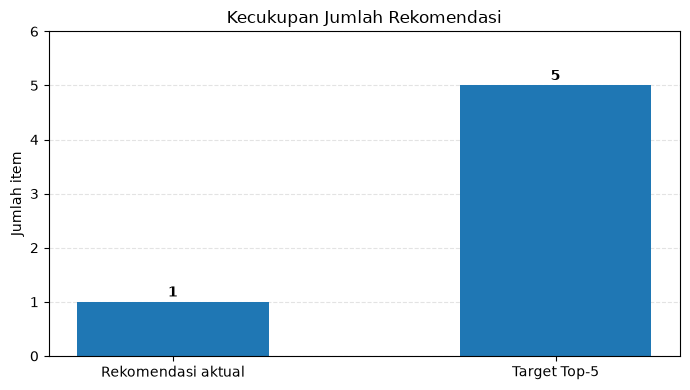

In [55]:

actual_count = len(recommended_item_ids)
target_count = 5

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    ["Rekomendasi aktual", "Target Top-5"],
    [actual_count, target_count],
    width=0.5
)

ax.set_ylim(0, 6)
ax.set_ylabel("Jumlah item")
ax.set_title("Kecukupan Jumlah Rekomendasi")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{int(bar.get_height())}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()


Berdasarkan visualisasi kecukupan jumlah rekomendasi, sistem menghasilkan 1 item rekomendasi aktual, sedangkan target yang ditetapkan adalah 5 item. Dengan demikian, sistem baru memenuhi 20% dari target jumlah rekomendasi. Kesenjangan ini menunjukkan bahwa kandidat yang dihasilkan dari tetangga terpilih masih terbatas, sehingga sistem belum mampu menyediakan lima pilihan item bagi pengguna. Oleh karena itu, diperlukan perbaikan pada proses pemilihan tetangga atau perluasan kandidat item agar sistem dapat menghasilkan rekomendasi yang lebih beragam. Namun, terpenuhinya jumlah rekomendasi saja tidak menjamin relevansi item, sehingga kualitas rekomendasi tetap perlu dinilai menggunakan metrik seperti Hit@5 dan NDCG@5.